In [1]:
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import utility.functions as fn
import src.simulation as sim
import src.analysis as an
import src.dataset as ds
import torch
from scipy.stats import norm
import pandas as pd
from utility.double_beta_spectrum import pdf_ratio2b
import matplotlib.pyplot as plt

In [39]:
channels = [3, 5, 9, 11, 13, 15, 17, 19]
signal_amps = [0.00231, 0.00180, 0.00126, 0.00130, 0.00179, 0.00134, 0.001139, 0.00112]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]

# Initialize output DataFrame
out_data = pd.DataFrame(columns=["channel_ID", "channel", "acceptance", "BI", "rp","J"])
out_data.to_csv('../outputs/BI_results_interp.csv', index=False)
n_deriv = 1

# Iterate over sorted channels
for index_channel in np.argsort(channel_ID):
    channel = channels[index_channel]
    signal_amp = signal_amps[index_channel]
    
    # Load datasets and channel specifications
    data_single, data_pileup, dt_pileup, r_pileup, E_pileups = ds.create_data_sets(channel, win_length=2000, shift=0, pos_prefix="_bis")
    H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct = np.hanning)
    
    # Convert data to PyTorch tensors
    S_torch = torch.tensor(S, dtype=torch.cfloat)
    H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
    w_torch = torch.tensor(w, dtype=torch.cfloat)
    t_torch = torch.linspace(0, 8e-4, 100, dtype=torch.cfloat)
    r_torch = torch.linspace(0., .5, 25, dtype=torch.cfloat)
    nps_torch = torch.tensor(nps, dtype=torch.cfloat)
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
    ratio_distribution = pdf_ratio2b(r_torch.numpy())
    ratio_distribution /= np.mean(ratio_distribution)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)

    # Loop over acceptance levels
    acceptances = [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]
    for acceptance in acceptances:
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500)
        #save_filter_function 
        np.save(f"../outputs/training_Js/channel_{channel}/J_{int(acceptance*100):d}_V2", np.array(J_values))
        np.save(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_V2", np.array([f1_opt, f2_opt]))
        # Compute PSD and BI
        # PSD_pileup,Amp_1_pileup, Amp_2_pileup= an.get_PSD_interpole(data_pileup, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv)
        # PSD_single, Amp_1_single, Amp_2_single  = an.get_PSD_interpole(data_single, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv)
        PSD_pileup,Amp_1_pileup, Amp_2_pileup = an.get_PSD_interpole_torch(data_pileup, H_unit_torch, torch.tensor(f1_opt), torch.tensor(f2_opt),window_fct = lambda x : torch.hann_window(x,periodic = False),n_deriv = n_deriv)
        PSD_single, Amp_1_single, Amp_2_single = an.get_PSD_interpole_torch(data_single, H_unit_torch, torch.tensor(f1_opt), torch.tensor(f2_opt),window_fct = lambda x : torch.hann_window(x,periodic = False),n_deriv = n_deriv)
        cut = np.percentile(PSD_single , 100 - acceptance * 100)
        rp = np.mean(PSD_pileup  < cut)
        BI = fn.calculate_BI(rp, 0.8)
        # Append results to DataFrame
        out_data = pd.concat([out_data, pd.DataFrame([{
            "channel_ID": channel_ID[index_channel],
            "channel": channel,
            "acceptance": acceptance,
            "BI": BI,
            "rp": rp,
            "J": J_values[-1]
        }])], ignore_index=True)
        # Save results to CSV
        out_data.to_csv('../outputs/BI_results_interp_v2.csv', index=False)
        print(f"Channel {channel}, Acceptance {acceptance}: J={J_values[-1]}, 1-rp={1-rp}, BI={BI}")

Step 0: J = 0.933053
Step 100: J = 0.269532
Step 200: J = 0.237754
Step 300: J = 0.227826
Step 400: J = 0.225931
Step 0: J = 0.894873
Step 100: J = 0.310352
Step 200: J = 0.281180
Step 300: J = 0.277002
Step 400: J = 0.276624
Step 0: J = 0.704489
Step 100: J = 0.200666
Step 200: J = 0.170066
Step 300: J = 0.162953
Step 400: J = 0.162772
Step 0: J = 0.925055
Step 100: J = 0.177131
Step 200: J = 0.142608
Step 300: J = 0.129487
Step 400: J = 0.124617
Step 0: J = 0.923094
Step 100: J = 0.221802
Step 200: J = 0.193622
Step 300: J = 0.186269
Step 400: J = 0.184082
Step 0: J = 0.848280
Step 100: J = 0.243968
Step 200: J = 0.205022
Step 300: J = 0.199395
Step 400: J = 0.199259
Step 0: J = 0.925751
Step 100: J = 0.263576
Step 200: J = 0.230749
Step 300: J = 0.223033
Step 400: J = 0.222832
Step 0: J = 0.931923
Step 100: J = 0.273789
Step 200: J = 0.252412
Step 300: J = 0.248782
Step 400: J = 0.248301


In [56]:
from utility.double_beta_spectrum import pdf_ratio2b
channels = [3, 5, 9, 11, 13, 15, 17, 19]
signal_amps = [0.00231, 0.00180, 0.00126, 0.00130, 0.00179, 0.00134, 0.001139, 0.00112]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
index_channel = 5
channel = channels[index_channel]
#signal_amps[index_channel]#0.01132#

# Load datasets and channel specifications
n_deriv = 1
H_unit, S, nps, w, pulse_factor = ds.get_channel_specs(channel, n_deriv=n_deriv, window_fct = np.hanning)
signal_amp = ds.get_amp_Q_val(channel)*pulse_factor
# Convert data to PyTorch tensors
S_torch = torch.tensor(S, dtype=torch.cfloat)
H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
w_torch = torch.tensor(w, dtype=torch.cfloat)
t_torch = torch.linspace(0, 8e-4, 100, dtype=torch.cfloat)
r_torch = torch.linspace(0., .5, 25, dtype=torch.cfloat)
nps_torch = torch.tensor(nps, dtype=torch.cfloat)
signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
ratio_distribution = pdf_ratio2b(r_torch.numpy())
ratio_distribution /= np.mean(ratio_distribution)
ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500)

data_single, data_pileup, dt_pileup, r_pileup, E_pileups = ds.create_data_sets(channel, win_length=2000, shift=8, pos_prefix="_bis")
PSD_pileup,Amp_1_pileup, Amp_2_pileup= an.get_PSD_interpole(data_pileup, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv)
PSD_single, Amp_1_single, Amp_2_single  = an.get_PSD_interpole(data_single, H_unit, f1_opt, f2_opt,window_fct = np.hanning,n_deriv = n_deriv)
# PSD_pileup_torch,Amp_1_pileup_torch, Amp_2_pileup_torch = an.get_PSD_interpole_torch(data_pileup, H_unit_torch, torch.tensor(f1_opt), torch.tensor(f2_opt),window_fct = lambda x : torch.hann_window(x,periodic = False),n_deriv = n_deriv)
# PSD_single_torch, Amp_1_single_torch, Amp_2_single_torch = an.get_PSD_interpole_torch(data_single, H_unit_torch, torch.tensor(f1_opt), torch.tensor(f2_opt),window_fct = lambda x : torch.hann_window(x,periodic = False),n_deriv = n_deriv)
cut = np.percentile(PSD_single , 100 - acceptance * 100)
rp = np.mean(PSD_pileup  < cut)
BI = fn.calculate_BI(rp, 0.8)
print(J_values[-1],1-rp,BI)

0.25010809302330017 0.27326666666666666 7.20800105516681e-05


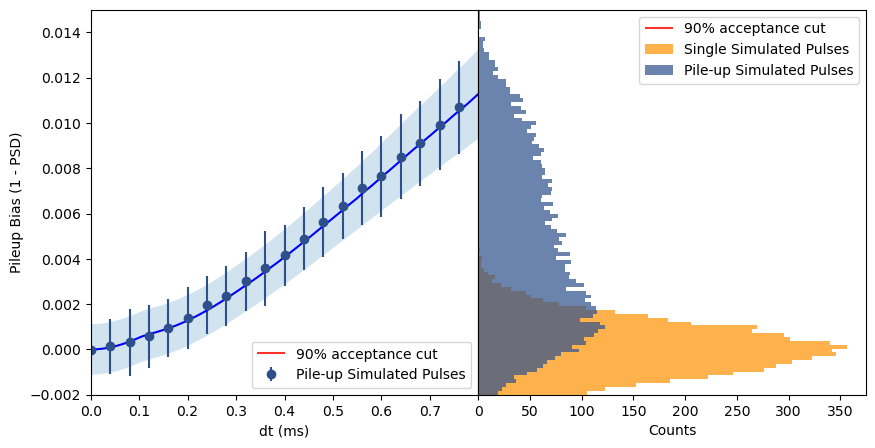

In [78]:
from src.plots import plot_biais_vs_dt
import matplotlib.pyplot as plt
S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
f1,f2  = torch.tensor(f1_opt,dtype=torch.cfloat), torch.tensor(f2_opt,dtype=torch.cfloat)
muY, sigmaY, mu1, mu2, var1, var2, cov12= an.compute_mu_sigma(f1, f2, S_H_delayed,r_torch, S_H, S2_over_nps, signal_amp, return_all=True)
mu = torch.mean(ratio_distribution_torch[:,None]*(1-muY.real), dim = 0).numpy().real
sigma = torch.sqrt(torch.mean(ratio_distribution_torch[:,None]*sigmaY**2, dim = 0)+torch.mean(ratio_distribution_torch[:,None]*(1-muY.real)**2, dim = 0)-mu**2).numpy().real
fig,ax,ax1=plot_biais_vs_dt(PSD_single, PSD_pileup, dt_pileup,cut=cut,bins=20)
ax.fill_between(t_torch.numpy()*1e3, mu-sigma, mu+sigma, alpha=0.2)
ax.plot(t_torch.numpy()*1e3, mu, color='blue', label='Expected PSD mean')
ax.set_xlim(0,0.8)
ax.set_ylim(-0.002,0.015)
plt.show()

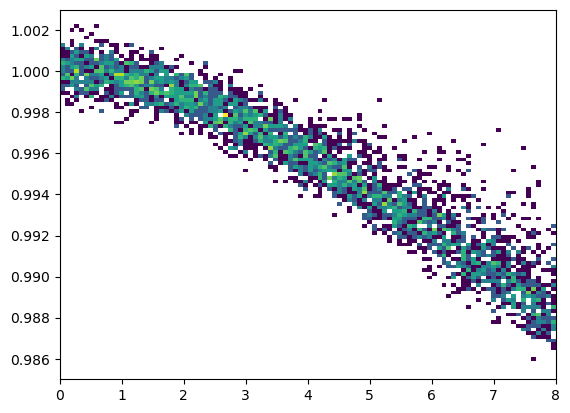

In [80]:
fpulses, signal_freq, noise_freq, generated_r, generated_dt = sim.simulate_frequency_pulses(S,nps,8.59898e-05,w,signal_scale = 0.001874,nsim=4000)
from torch.utils.data import TensorDataset
dataset_simu = TensorDataset(torch.from_numpy(np.fft.ifft(fpulses, axis=1).real.astype(np.float32)))
PSD_simu,Amp_1_simu, Amp_2_simu = an.get_PSD_interpole(dataset_simu, H_unit, f1_opt, f2_opt)
plt.hist2d(generated_dt*1e4,  PSD_simu, bins=100,range = [[0,8],[0.985,1.003]],norm="log")
plt.show()

In [5]:
win_length = 2000
shift=-2
channel = 15
data_single_noinj = ds.BinaryDataset(ds.find_file(f"000813_20230628T161508_{channel:03}_???.bin"), win_length, data_single.positions, win_shift=win_length // 2 - shift)
nps = an.create_NPS(data_single_noinj, rms_thr = 0.0005,n_deriv = 0,window_fct = np.hanning)
nps.tofile(f"/media/mp274748/Transcend/data/LSC/RUN9_pulse_injected_new/channel15/dif/raw_noise_d0.bin_spec.bin")

